# Proyecto Process Mining
Enzo Joaquín Santillán Málaga


## Actividad 1: Data engineering
### 1. ¿Qué columna o combinación de columnas usarías como identificador de caso (sesión, conversación, usuario o usuario más día), y qué pasaría con las variantes si eligieras otra?
El identificador de caso mas conveniente es el número del archivo csv, porque cada archivo es una conversación completa entre bot y usuario. Los datos no contienen usuario ni fecha reales, así que no se puede usar usuario ni usuario+día como identificador. Si se eligiera Falante se tendrían solo 2 casos enormes que mezclan todas las conversaciones. Si se eligiera Tipo o Subtipo de Touchpoint, que son las actividades, cada caso agruparía todas las apariciones de una misma actividad y habría una sola variante por caso. Con Mensagem, cada evento sería su propio caso por ser texto casi único. En todos estos casos las trazas no representarían un recorrido real, y el análisis de variantes no tendría sentido.

### 2. Los mensajes han sido transformados en actividades usando touchpoints ¿Crees que hay otra forma de crear actividades con un nivel de abstracción adecuado (por ejemplo intención del usuario, tipo de respuesta del bot), y qué técnica otra usarías para etiquetarlos?
Sí, se pueden crear actividades de otra forma. Del lado del usuario usaría la intención (consulta de producto, reclamo, solicitud de humano, cierre), etiquetada con un LLM en modo zero-shot sobre una lista cerrada de categorías. Del lado del bot clasificaría el tipo de respuesta (concluyente, con duda, desviada, segura) con el mismo método. El análisis de sentimiento de los mensajes del usuario lo usaría como un atributo del evento y no como actividad, para detectar en qué punto de la conversación el cliente se frustra. Mantendría entre 5 y 10 etiquetas por lado para que las variantes sean interpretables, y validaría una muestra manualmente.

### 3. Si dos mensajes tienen el mismo timestamp o este solo tiene precisión de segundos, ¿cómo garantizas el orden correcto dentro de cada caso? ¿qué regla aplicarías para este caso?
El resolver este caso seria algo simple, el algoritmo se tiene que basar en el orden de quien ha mandado el mensaje. Dentro del csv se puede ver como hay un orden estricto de respuesta bot y respuesta usuario. Por lo que un algoritmo que ordene las actividades segun el orden del orador puede asegurar que no se cometan errores relacionados al timestamp.

### 4. ¿Cómo derivarías un evento de inicio y de fin de conversación si el log no los trae?
Crearía dos eventos sintéticos por caso. Inicio de conversación se coloca antes del primer mensaje, ya que el primer evento de cada caso es el saludo del bot. Fin de conversación se coloca tras el último mensaje, y su causa se infiere así: si el último mensaje se clasifica como cierre o despedida, la conversación terminó con normalidad; si hay una inactividad prolongada o el usuario deja de responder, es un abandono. No exigiría un cierre de ambos lados, porque en los datos 5 de 13 conversaciones terminan en abandono, inactividad, ignorar sugerencias o dificultad, sin despedida. El motivo de fin se guarda como atributo para poder comparar variantes exitosas y fallidas.


## Ejemplo de transformación de los csvs a log

In [1]:
import re
from pathlib import Path

import pandas as pd
import pm4py
import numpy as np                  # números aleatorios para el log de ejemplo
import matplotlib.pyplot as plt     # gráficos
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 300)

# Funciona tanto si el notebook se ejecuta desde la carpeta del proyecto como desde su carpeta padre
CARPETA = next(p for p in (Path("conversas_250505"), Path("Proyecto_ProcessM/conversas_250505")) if p.is_dir())
FECHA_BASE = pd.Timestamp("2025-05-05")

partes = []
for archivo in CARPETA.glob("DIALOGO*.csv"):
    caso = re.search(r"(\d+)", archivo.stem).group(1)
    df = pd.read_csv(archivo, encoding="utf-8-sig").drop(columns=["Mensagem"])
    df["case:concept:name"] = caso
    df["event_index"] = range(len(df))
    partes.append(df)

df_log = pd.concat(partes, ignore_index=True).rename(columns={
    "Falante": "org:resource",
    "Subtipo de Touchpoint": "concept:name",
    "Tipo de Touchpoint": "fase",
})
df_log["actividad_falante"] = df_log["org:resource"] + " | " + df_log["concept:name"]
# timestamp sintético: solo sirve para ordenar, no para medir duraciones
df_log["time:timestamp"] = FECHA_BASE + pd.to_timedelta(df_log["event_index"], unit="s")
df_log = df_log.sort_values(["case:concept:name", "event_index"],
                            key=lambda s: s.astype(int)).reset_index(drop=True)
df_log = pm4py.format_dataframe(df_log, case_id="case:concept:name",
                                activity_key="concept:name", timestamp_key="time:timestamp")

log = pm4py.convert_to_event_log(df_log)
print(f"Casos: {len(log)} | Eventos: {len(df_log)}")




  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




Casos: 13 | Eventos: 159


## Actividad 2: Análisis del flujo 
### 0. Cargar event_log_en.csv


In [2]:
def cargar_log(ruta, col_caso, col_actividad, col_tiempo, col_recurso=None):
    """Lee un log de eventos (CSV o XES) y estandariza los nombres de las columnas."""
    # 1. Leer el archivo según su extensión
    if ruta.endswith(".csv"):
        tabla = pd.read_csv(ruta)
    elif ruta.endswith(".xes") or ruta.endswith(".xes.gz"):
        import pm4py                      # solo se necesita para leer archivos XES
        tabla = pm4py.read_xes(ruta)
    else:
        raise ValueError("Formato no soportado: use un archivo .csv o .xes")

    # 2. Renombrar las columnas a los nombres estándar
    nombres_nuevos = {col_caso: "caso", col_actividad: "actividad", col_tiempo: "tiempo"}
    if col_recurso is not None and col_recurso in tabla.columns:
        nombres_nuevos[col_recurso] = "recurso"
    tabla = tabla.rename(columns=nombres_nuevos)

    # 3. Convertir el tiempo a fecha y hora, y el caso a texto
    tabla["tiempo"] = pd.to_datetime(tabla["tiempo"], format="%d/%m/%Y %H:%M", utc=True)
    tabla["tiempo"] = tabla["tiempo"].dt.tz_localize(None)
    tabla["caso"] = tabla["caso"].astype(str)

    # 4. Ordenar los eventos de cada caso por tiempo (el orden de llegada puede no ser el cronológico)
    tabla = tabla.sort_values(["caso", "tiempo"], kind="mergesort")
    tabla = tabla.reset_index(drop=True)
    return tabla

RUTA_LOG = "event_log_en.csv"

COL_CASO = "CASE_ID"            
COL_ACTIVIDAD = "ACTIVITY_EN"     
COL_TIEMPO = "START_TIMESTAMP"        
COL_RECURSO = "RECURSO"    

log = cargar_log(RUTA_LOG, COL_CASO, COL_ACTIVIDAD, COL_TIEMPO, COL_RECURSO)
log = log.drop(columns=["Unnamed: 0"])
log.head(10)

,caso,EVENT_ID,ACTIVITY,tiempo,END_TIMESTAMP,recurso,AGENTE,actividad
0,00044a5f68c82574,1,SAUDAÇÃO INICIAL DO CHATBOT,2025-07-11 04:53:00,11/07/2025 04:53,NaN,ai,Initial chatbot greeting
1,00044a5f68c82574,2,RESPOSTA COM INSATISFAÇÃO,2025-07-11 04:53:00,11/07/2025 04:57,NaN,human,Response with dissatisfaction
2,00044a5f68c82574,3,ENCAMINHAMENTO OUTROS CANAIS,2025-07-11 04:57:00,11/07/2025 04:57,cartoes_credito_outros_produtos,ai,Referral to other channels
3,00044a5f68c82574,4,RESPOSTA COM INSATISFAÇÃO,2025-07-11 04:57:00,11/07/2025 05:00,NaN,human,Response with dissatisfaction
4,00044a5f68c82574,5,ENCAMINHAMENTO OUTROS CANAIS,2025-07-11 05:00:00,11/07/2025 05:00,cartoes_credito_outros_produtos,ai,Referral to other channels
5,00044a5f68c82574,6,RESPOSTA COM INSATISFAÇÃO,2025-07-11 05:00:00,11/07/2025 05:03,NaN,human,Response with dissatisfaction
6,00044a5f68c82574,7,ENCAMINHAMENTO OUTROS CANAIS,2025-07-11 05:03:00,11/07/2025 05:04,cartoes_credito_outros_produtos,ai,Referral to other channels
7,00044a5f68c82574,8,ENTREGA DE INFORMAÇÕES,2025-07-11 05:04:00,11/07/2025 05:06,NaN,human,Information delivery
8,00044a5f68c82574,9,ENCAMINHAMENTO OUTROS CANAIS,2025-07-11 05:06:00,11/07/2025 05:07,cartoes_credito_outros_produtos,ai,Referral to other channels
9,00044a5f68c82574,10,REDIRECIONAMENTO A OUTRO CANAL,2025-07-11 05:07:00,11/07/2025 05:09,NaN,human,Redirection to other channel


In [3]:
def revisar_calidad(log):
    """Revisa problemas típicos de calidad de un log y devuelve un resumen."""
    resultados = {}
    resultados["Filas (eventos)"] = len(log)
    resultados["Casos"] = log["caso"].nunique()
    resultados["Actividades distintas"] = log["actividad"].nunique()
    resultados["Casos sin identificador"] = int(log["caso"].isna().sum())
    resultados["Eventos sin actividad"] = int(log["actividad"].isna().sum())
    resultados["Eventos sin fecha"] = int(log["tiempo"].isna().sum())

    # Eventos repetidos exactamente (mismo caso, actividad y momento)
    repetidos = log.duplicated(subset=["caso", "actividad", "tiempo"])
    resultados["Eventos duplicados"] = int(repetidos.sum())

    # Eventos con la misma marca de tiempo que el evento anterior del mismo caso
    diferencias = log.groupby("caso")["tiempo"].diff()
    resultados["Eventos con la misma hora que el anterior"] = int((diferencias == pd.Timedelta(0)).sum())

    # Casos con un solo evento no permiten medir ningún tiempo
    eventos_por_caso = log.groupby("caso").size()
    resultados["Casos con un solo evento"] = int((eventos_por_caso == 1).sum())
    return pd.Series(resultados)

revisar_calidad(log)

Filas (eventos)                              2070
Casos                                         300
Actividades distintas                          33
Casos sin identificador                         0
Eventos sin actividad                           2
Eventos sin fecha                               0
Eventos duplicados                              0
Eventos con la misma hora que el anterior     536
Casos con un solo evento                        0
dtype: int64

In [4]:

antes = len(log)
log = log.dropna(subset=["actividad"]).reset_index(drop=True)
print(f"Eventos eliminados: {antes - len(log)} | Eventos restantes: {len(log)}")


Eventos eliminados: 2 | Eventos restantes: 2068


### 1. Patrones de control del flujo: Identifica en el log tratado un caso de secuencia, uno de elección exclusiva (XOR), uno de paralelismo (AND) y un bucle entre touchpoints. ¿Qué evidencia en las trazas respalda cada uno?
1.- Secuencia: La primera relación que encontramos es al inicio con la secuencia de Initial chatbot greeting y luego suele ir Clarification of intent - Directed flows - Spontaneous thanks.

2.- XOR: Una secuencia de actividades que se ve repetidamente en el log es Response with dissatisfaction (163 veces), a Clarification of intent (56) o a Information delivery (55).

3.- AND: Hay evidencia en el log de posible AND con Delivery of an unresolved response y Solution delivery (9 casos en un orden y 9 en el otro) ambos aparecen en orden intercambiado, pero esto de todas maneras no demuestra que sean una compuerta AND, mas que nada por el timestamp que no son actividades simultaneas. 

4.- Bucle: En este caso se ve un bucle bastante claro que es Response with dissatisfaction <-> Referral to other channels, con 273 transiciones en un sentido y 227 en el otro. 

### 2. Bucles y retrabajo: Algunos touchpoints se repiten dentro de una conversación (reformulaciones del usuario, repreguntas del bot). ¿Cómo distingues un bucle legítimo (mensajes que se refieren al mismo tema) de un fallo del chatbot (el bot hizo repitió la pregunta)? explica tu respuesta, cada respuesta es única para extra pregunta

Con este log, que no incluye el texto de los mensajes, distingo ambos bucles por tres señales. Primera: quién repite. Un usuario que reformula, como en Clarification of intent, es legítimo, mientras que el bot que repite la misma actividad sin cambios, como Referral to other channels, es sospechoso. Segunda: si hay progreso entre repeticiones, por ejemplo Response with data o Solution delivery. Tercera: el desenlace. Entre los 111 casos con 2 o más Referral to other channels, solo 6 terminan en agradecimiento y 87 en queja o insatisfacción, lo que indica fallo del bot. Con el texto de los mensajes, mediría además la similitud entre ellos.

### 3. Variantes: ¿Cuántas variantes hay y qué porcentaje de casos cubren las 5 más frecuentes? ¿Qué decisión tomarías sobre las variantes raras (filtrar, agrupar o conservar)?

In [5]:
def construir_trazas(log):
    """Crea una tabla con una fila por caso: su traza, su inicio, su fin y su duración en días."""
    filas = []
    for id_caso, eventos_del_caso in log.groupby("caso"):
        lista_actividades = list(eventos_del_caso["actividad"])
        primer_momento = eventos_del_caso["tiempo"].iloc[0]
        ultimo_momento = eventos_del_caso["tiempo"].iloc[-1]
        segundos = (ultimo_momento - primer_momento).total_seconds()

        fila = {
            "caso": id_caso,
            "traza": " > ".join(lista_actividades),
            "primera_actividad": lista_actividades[0],
            "ultima_actividad": lista_actividades[-1],
            "n_eventos": len(lista_actividades),
            "inicio": primer_momento,
            "fin": ultimo_momento,
            "duracion_dias": segundos / 86400,        # 86400 segundos tiene un día
        }
        filas.append(fila)
    return pd.DataFrame(filas)


def tabla_variantes(trazas):
    """Agrupa los casos por traza y calcula cuántos casos tiene cada variante."""
    grupos = trazas.groupby("traza")
    variantes = pd.DataFrame({
        "casos": grupos.size(),
        "duracion_media_dias": grupos["duracion_dias"].mean(),
    }).reset_index()
    variantes = variantes.sort_values("casos", ascending=False).reset_index(drop=True)
    variantes["porcentaje"] = 100 * variantes["casos"] / variantes["casos"].sum()
    variantes["acumulado"] = variantes["porcentaje"].cumsum()
    variantes.insert(0, "variante", range(1, len(variantes) + 1))
    return variantes


def variantes_para_cubrir(variantes, porcentaje_objetivo):
    """Cuenta cuántas variantes (de la más frecuente a la menos frecuente) hacen falta para cubrir un porcentaje de casos."""
    for posicion in range(len(variantes)):
        if variantes["acumulado"].iloc[posicion] >= porcentaje_objetivo:
            return posicion + 1
    return len(variantes)

trazas = construir_trazas(log)
variantes = tabla_variantes(trazas)

print("Casos:", len(trazas), "| Variantes distintas:", len(variantes))
variantes[["variante", "casos", "porcentaje", "acumulado", "duracion_media_dias", "traza"]].round(1)

Casos: 300 | Variantes distintas: 210


,variante,casos,porcentaje,acumulado,duracion_media_dias,traza
0,1,21,7.0,7.0,0.0,Initial chatbot greeting > Response with dissatisfaction > Referral to other channels > Response with dissatisfaction > Referral to other channels > Response with dissatisfaction
1,2,11,3.7,10.7,0.0,Initial chatbot greeting > Response with dissatisfaction > Referral to other channels > Response with dissatisfaction
2,3,11,3.7,14.3,0.0,Initial chatbot greeting > Response with dissatisfaction > Referral to other channels > Response with dissatisfaction > Referral to other channels > Closing with complaint
3,4,8,2.7,17.0,0.0,Initial chatbot greeting > Response with dissatisfaction > Referral to other channels > Closing with complaint
4,5,6,2.0,19.0,0.0,Initial chatbot greeting > Clarification of intent > Directed flows > Spontaneous thanks
...,...,...,...,...,...,...
205,206,1,0.3,98.7,0.0,Initial chatbot greeting > Response with dissatisfaction > Solution delivery > Response with dissatisfaction > Referral to other channels > Response with dissatisfaction > Response with data > Response with dissatisfaction
206,207,1,0.3,99.0,0.0,Initial chatbot greeting > Response with dissatisfaction > Solution delivery > Response with dissatisfaction > Response with data > Response with dissatisfaction
207,208,1,0.3,99.3,0.0,Initial chatbot greeting > Solution rejection > Delivery of an unresolved response > Solution rejection > Delivery of an unresolved response > Stress detection > Delivery of an unresolved response > Closing with complaint
208,209,1,0.3,99.7,0.0,Initial chatbot greeting > Solution rejection > Delivery of an unresolved response > Solution rejection > Response with data > Request for alternative channel > Referral to other channels > Spontaneous thanks


In [6]:
cantidad = variantes_para_cubrir(variantes, 30)
cantidad1 = variantes_para_cubrir(variantes, 40)
cantidad2 = variantes_para_cubrir(variantes, 50)
cantidad3 = variantes_para_cubrir(variantes, 60)
cantidad4 = variantes_para_cubrir(variantes, 70)
cantidad5 = variantes_para_cubrir(variantes, 80)
print("variantes necesarias para cubrir el 30% de los casos:", cantidad, "de", len(variantes))
print("variantes necesarias para cubrir el 40% de los casos:", cantidad1, "de", len(variantes))
print("variantes necesarias para cubrir el 50% de los casos:", cantidad2, "de", len(variantes))
print("variantes necesarias para cubrir el 60% de los casos:", cantidad3, "de", len(variantes))
print("variantes necesarias para cubrir el 70% de los casos:", cantidad4, "de", len(variantes))
print("variantes necesarias para cubrir el 80% de los casos:", cantidad5, "de", len(variantes))

variantes necesarias para cubrir el 30% de los casos: 14 de 210
variantes necesarias para cubrir el 40% de los casos: 31 de 210
variantes necesarias para cubrir el 50% de los casos: 60 de 210
variantes necesarias para cubrir el 60% de los casos: 90 de 210
variantes necesarias para cubrir el 70% de los casos: 120 de 210
variantes necesarias para cubrir el 80% de los casos: 151 de 210


Los 5 casos más frecuentes comprenden el 19% del total de casos, habiendo un total de 210 variantes las 31 mas grandes ya comprenden el aproximadamente el 40% del total, luego de eso cada aumento de 10% aumenta 30 variantes lo que significa que cada variante es de 0.3% que significa que representa solo 1 caso. Por eso el log conviene que se quede con las 31 variantes mas grandes, para evitar variantes unicas.

In [7]:
# Conservar solo los casos de las 31 variantes más frecuentes
N_VARIANTES = 31
traza_top = variantes["traza"].iloc[:N_VARIANTES]

trazas_filtradas = trazas[trazas["traza"].isin(traza_top)].copy()
casos_validos = set(trazas_filtradas["caso"])
log_filtrado = log[log["caso"].isin(casos_validos)].reset_index(drop=True)
variantes_filtradas = tabla_variantes(trazas_filtradas)

print(f"Casos: {len(trazas)} -> {len(trazas_filtradas)} | Variantes: {len(variantes)} -> {len(variantes_filtradas)}")


Casos: 300 -> 121 | Variantes: 210 -> 31


## Actividad 3: Process discovery
### 1. Descubre el proceso con Alpha miner en pm4py y evalúa las métricas sound del modelo descubierto

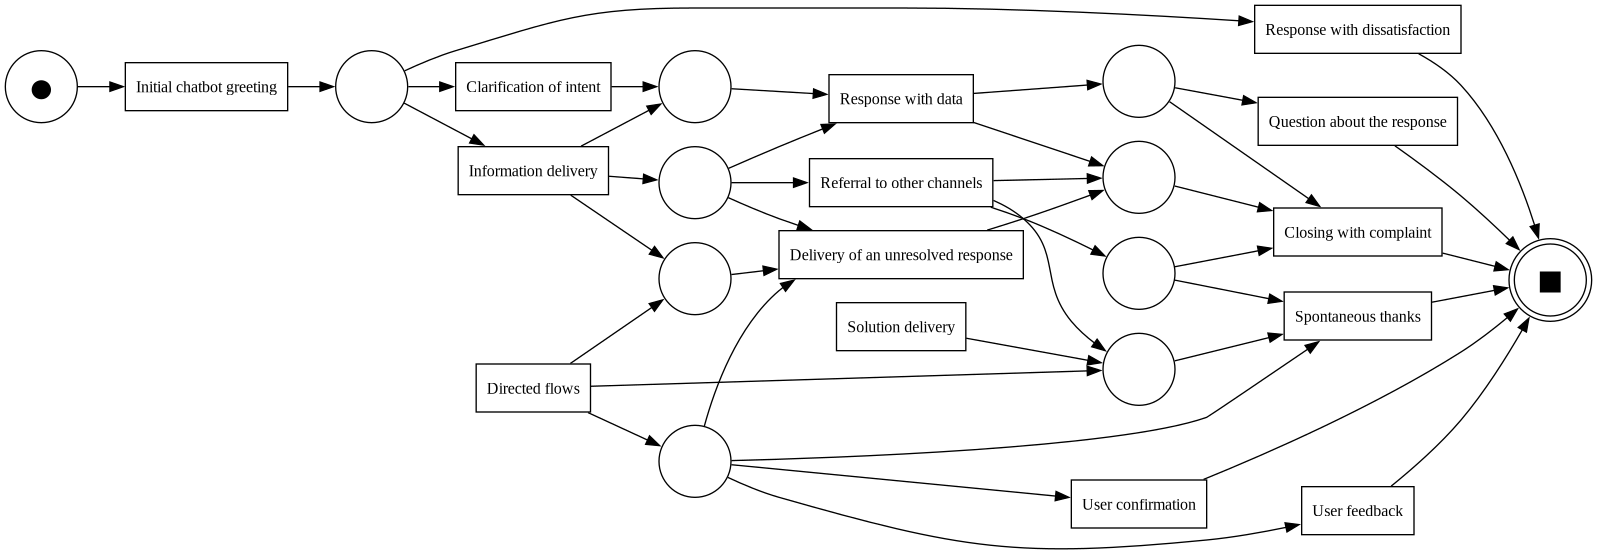

Lugares: 11 | Transiciones: 14
Es una workflow net: False
Es sound: False
Transiciones sin lugar de entrada: ['Solution delivery', 'Directed flows']


Fitness                 0.494
Trazas conformes (%)    0.000
Precisión               0.470
Generalización          0.624
Simplicidad             0.455
dtype: float64

In [8]:
import warnings
from IPython.display import Image, display

# Ocultamos advertencias para que la salida sea más clara
warnings.filterwarnings("ignore")
pm4py.util.constants.SHOW_PROGRESS_BAR = False

def mostrar_modelo(red, marcado_inicial, marcado_final, archivo="modelo.png"):
    # Guarda el modelo como imagen y la muestra en el notebook
    pm4py.save_vis_petri_net(red, marcado_inicial, marcado_final, archivo)
    display(Image(archivo))


# Función que calcula las cuatro dimensiones de calidad de un modelo respecto a un log
def calcular_calidad(log, red, marcado_ini, marcado_fin):
    fitness = pm4py.fitness_token_based_replay(log, red, marcado_ini, marcado_fin)
    precision = pm4py.precision_token_based_replay(log, red, marcado_ini, marcado_fin)
    generalizacion = pm4py.generalization_tbr(log, red, marcado_ini, marcado_fin)
    simplicidad = pm4py.simplicity_petri_net(red, marcado_ini, marcado_fin)
    resultado = {
        "Fitness": round(fitness["log_fitness"], 3),
        "Trazas conformes (%)": round(fitness["percentage_of_fitting_traces"], 1),
        "Precisión": round(precision, 3),
        "Generalización": round(generalizacion, 3),
        "Simplicidad": round(simplicidad, 3),
    }
    return resultado


# Log filtrado (31 variantes más frecuentes) en el formato que pide pm4py
log_pm = pm4py.format_dataframe(log_filtrado.copy(), case_id="caso",
                                activity_key="actividad", timestamp_key="tiempo")

red_alpha, marcado_ini_alpha, marcado_fin_alpha = pm4py.discover_petri_net_alpha(log_pm)
mostrar_modelo(red_alpha, marcado_ini_alpha, marcado_fin_alpha, "modelo_alpha.png")

print("Lugares:", len(red_alpha.places), "| Transiciones:", len(red_alpha.transitions))
print("Es una workflow net:", pm4py.analysis.check_is_workflow_net(red_alpha))
sound_alpha = pm4py.check_soundness(red_alpha, marcado_ini_alpha, marcado_fin_alpha)[0]
print("Es sound:", sound_alpha)

# Transiciones sin lugar de entrada: pueden dispararse en cualquier momento
sin_entrada = [t.label for t in red_alpha.transitions if len(t.in_arcs) == 0]
print("Transiciones sin lugar de entrada:", sin_entrada)

calidad_alpha = calcular_calidad(log_pm, red_alpha, marcado_ini_alpha, marcado_fin_alpha)
pd.Series(calidad_alpha)

El modelo de Alpha miner no es sound, ni siquiera es una workflow net: Directed flows y Solution delivery quedan sin lugar de entrada, así que pueden ejecutarse en cualquier momento, y además Alpha no sabe representar bucles cortos como Response with dissatisfaction <-> Referral to other channels, que es justo el patrón más repetido del log. Por eso ninguna traza encaja completa (0% de trazas conformes) y el fitness es de solo 0.494. La precisión (0.470) y la generalización (0.624) no son confiables porque el fitness es bajo, y la simplicidad (0.455) también es baja.

### 2. Descubre el proceso con Inductive miner en pm4py y evalúa las métricas sound del modelo descubierto

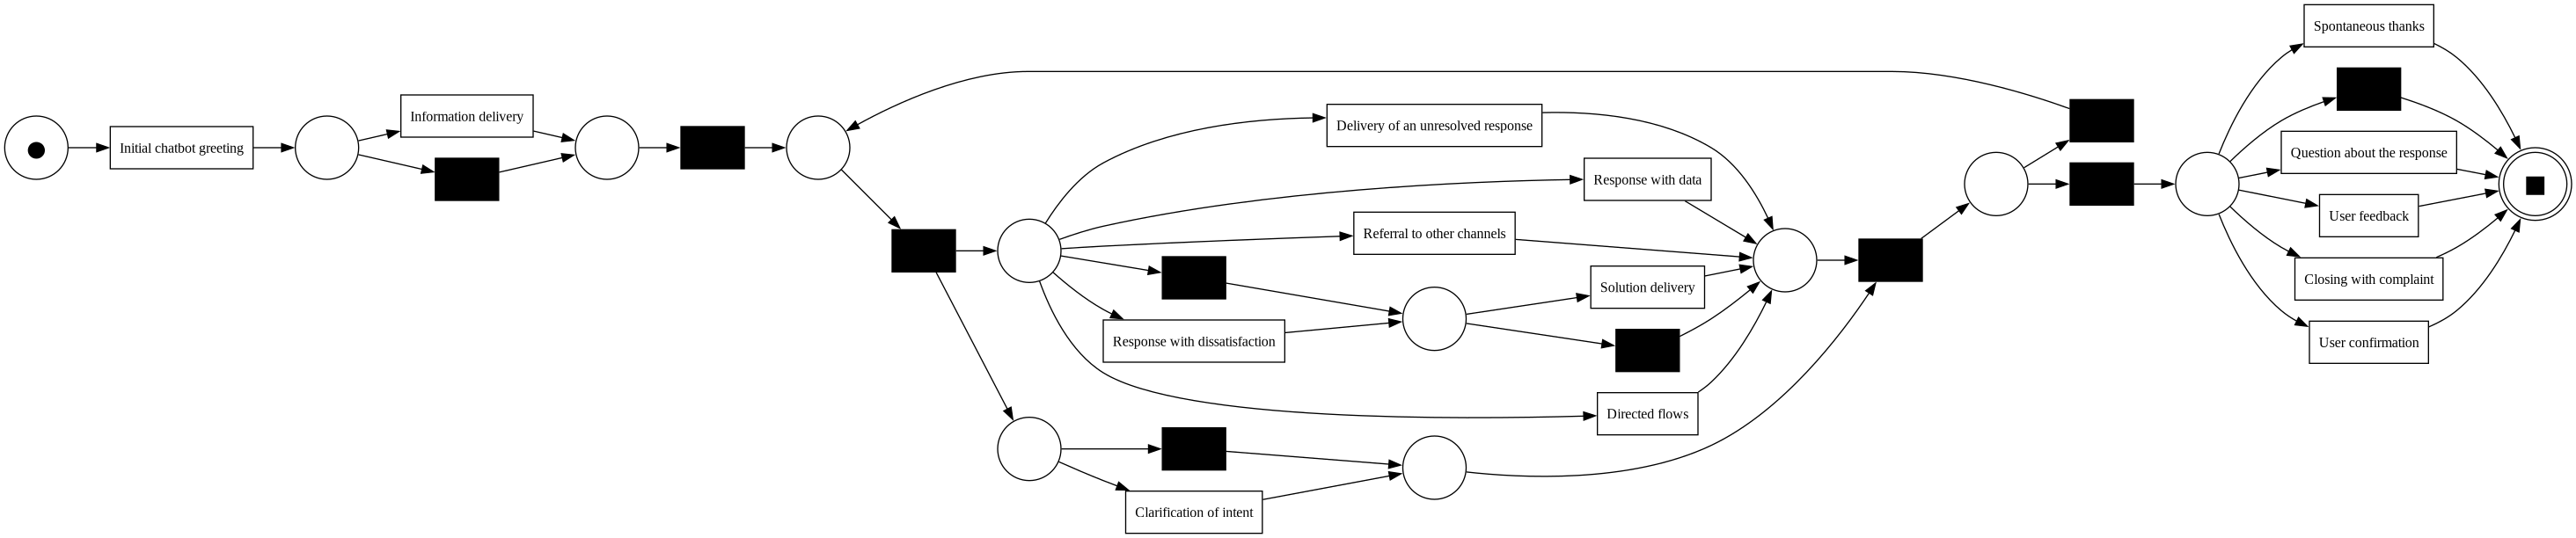

Lugares: 12 | Transiciones: 24 ( 10 invisibles )
Es una workflow net: True
Es sound: True


Fitness                   1.000
Trazas conformes (%)    100.000
Precisión                 0.217
Generalización            0.723
Simplicidad               0.562
dtype: float64

In [9]:
red_ind, marcado_ini_ind, marcado_fin_ind = pm4py.discover_petri_net_inductive(log_pm)
mostrar_modelo(red_ind, marcado_ini_ind, marcado_fin_ind, "modelo_inductive.png")

invisibles = sum(1 for t in red_ind.transitions if t.label is None)
print("Lugares:", len(red_ind.places), "| Transiciones:", len(red_ind.transitions), "(", invisibles, "invisibles )")
print("Es una workflow net:", pm4py.analysis.check_is_workflow_net(red_ind))
sound_ind = pm4py.check_soundness(red_ind, marcado_ini_ind, marcado_fin_ind)[0]
print("Es sound:", sound_ind)

calidad_ind = calcular_calidad(log_pm, red_ind, marcado_ini_ind, marcado_fin_ind)
pd.Series(calidad_ind)

El modelo de Inductive miner sí es sound: es una workflow net y siempre puede llegar al final sin bloqueos, porque el algoritmo construye el modelo por bloques. Reproduce el 100% de las trazas (fitness 1.0) y generaliza mejor (0.723). El costo es la precisión, que baja a 0.217: para cubrir todo usa 10 transiciones invisibles y bucles que permiten muchos más recorridos de los que aparecen en el log. La simplicidad es de 0.562.

### 3. Compara cuál de los dos modelos es mejor?

In [10]:
tabla_calidad = pd.DataFrame([calidad_alpha, calidad_ind], index=["Alpha miner", "Inductive miner"])
tabla_calidad["Sound"] = [sound_alpha, sound_ind]
tabla_calidad

,Fitness,Trazas conformes (%),Precisión,Generalización,Simplicidad,Sound
Alpha miner,0.494,0.0,0.470,0.624,0.455,False
Inductive miner,1.000,100.0,0.217,0.723,0.562,True


El mejor modelo es el de Inductive miner. Es sound y reproduce todas las conversaciones (fitness 1.0 frente a 0.494), mientras que el de Alpha no es sound y no explica ninguna traza completa, por lo que sus otras métricas no se pueden interpretar. Inductive también gana en generalización (0.723) y simplicidad (0.562). Su punto débil es la precisión (0.217), ya que permite más comportamiento del que se observa; para mejorarla se podría probar un noise_threshold mayor que 0.

## Actividad 4: Análisis de conformidad
### 1. ¿qué significa que una conversación del chatbot “es conforme” con un modelo de proceso? Da un ejemplo de un diálogo que sí conforma y uno que no.


In [11]:
# Log completo (300 conversaciones) en el formato de pm4py
log_pm_todo = pm4py.format_dataframe(log.copy(), case_id="caso",
                                     activity_key="actividad", timestamp_key="tiempo")
log_eventos = pm4py.convert_to_event_log(log_pm_todo)

# Calculamos los alineamientos óptimos del log contra el modelo de Inductive miner
alineamientos = pm4py.conformance_diagnostics_alignments(
    log_eventos, red_ind, marcado_ini_ind, marcado_fin_ind
)

# Función auxiliar para clasificar cada paso del alineamiento.
# Cada paso es un par (etiqueta en el log, etiqueta en el modelo)
def clasificar_movimiento(par):
    etiqueta_log = par[0]
    etiqueta_modelo = par[1]
    if etiqueta_modelo is None:
        return "transición invisible"
    if etiqueta_log == ">>":
        return "movimiento de modelo (actividad omitida)"
    if etiqueta_modelo == ">>":
        return "movimiento de log (actividad de más)"
    return "sincrónico"


# Construimos una tabla resumen de los alineamientos, caso por caso
filas_alineamiento = []
posicion = 0
for traza in log_eventos:
    resultado = alineamientos[posicion]
    id_caso = traza.attributes["concept:name"]

    # Contamos cuántos movimientos de cada tipo tiene el alineamiento
    movimientos_log = 0
    movimientos_modelo = 0
    for par in resultado["alignment"]:
        tipo = clasificar_movimiento(par)
        if tipo == "movimiento de log (actividad de más)":
            movimientos_log = movimientos_log + 1
        if tipo == "movimiento de modelo (actividad omitida)":
            movimientos_modelo = movimientos_modelo + 1

    fila = {
        "Caso": id_caso,
        "Conforme": resultado["fitness"] == 1.0,
        "Fitness alignment": round(resultado["fitness"], 3),
        "Movimientos de log": movimientos_log,
        "Movimientos de modelo": movimientos_modelo,
    }
    filas_alineamiento.append(fila)
    posicion = posicion + 1

tabla_alineamientos = pd.DataFrame(filas_alineamiento)
print("Conversaciones conformes:", tabla_alineamientos["Conforme"].sum(), "de", len(tabla_alineamientos),
      "(", round(100 * tabla_alineamientos["Conforme"].mean(), 1), "% )")
print("Fitness medio por conversación:", round(tabla_alineamientos["Fitness alignment"].mean(), 3))
print()

# Mostramos el alineamiento de una conversación conforme y de una no conforme
casos_a_mostrar = ["f2c4ea44417ddd9e", "52af3e9b45522fd2"]

posicion = 0
for traza in log_eventos:
    id_caso = traza.attributes["concept:name"]
    if id_caso in casos_a_mostrar:
        resultado = alineamientos[posicion]
        print("Caso", id_caso, "| fitness:", round(resultado["fitness"], 3))
        for par in resultado["alignment"]:
            if par[1] is not None:            # ocultamos las transiciones invisibles
                print("   Log:", par[0], "| Modelo:", par[1], "->", clasificar_movimiento(par))
        print()
    posicion = posicion + 1

Conversaciones conformes: 204 de 300 ( 68.0 % )
Fitness medio por conversación: 0.939

Caso 52af3e9b45522fd2 | fitness: 0.8
   Log: Initial chatbot greeting | Modelo: Initial chatbot greeting -> sincrónico
   Log: Information delivery | Modelo: Information delivery -> sincrónico
   Log: Referral to other channels | Modelo: Referral to other channels -> sincrónico
   Log: Solution rejection | Modelo: >> -> movimiento de log (actividad de más)

Caso f2c4ea44417ddd9e | fitness: 1.0
   Log: Initial chatbot greeting | Modelo: Initial chatbot greeting -> sincrónico
   Log: Information delivery | Modelo: Information delivery -> sincrónico
   Log: Directed flows | Modelo: Directed flows -> sincrónico
   Log: Spontaneous thanks | Modelo: Spontaneous thanks -> sincrónico



Una conversación es conforme cuando el modelo puede reproducirla completa, de inicio a fin, sin saltarse ni agregar ningún paso, es decir, cuando su alineamiento tiene fitness 1. Comparando las 300 conversaciones con el modelo de Inductive miner, 204 (68%) son conformes.

1.- Sí conforma: el caso f2c4ea44417ddd9e (Initial chatbot greeting > Information delivery > Directed flows > Spontaneous thanks). Todos sus pasos son movimientos sincrónicos, así que el modelo la reproduce completa.

2.- No conforma: el caso 52af3e9b45522fd2 (Initial chatbot greeting > Information delivery > Referral to other channels > Solution rejection). El usuario rechaza la solución, y esa actividad no existe en el modelo, así que aparece como un movimiento de log y el fitness baja a 0.8. Las desviaciones más comunes son de este tipo: actividades poco frecuentes que quedaron fuera al filtrar las variantes raras, como Cancellation request, Fraud report o Request for alternative channel.


### 2. ¿Con qué compararías el log: con el modelo que descubriste o con el flujo ideal que diseñó el equipo del chatbot? sustenta tu respuesta


Lo compararía con el flujo ideal que diseñó el equipo del chatbot. El modelo descubierto sale del mismo log, así que compararlo contra ese log es circular: en la Actividad 3 el modelo de Inductive miner reprodujo el 100% de las trazas filtradas, incluidos los bucles de Response with dissatisfaction <-> Referral to other channels, porque aprende las fallas como si fueran parte del proceso. El flujo ideal, en cambio, describe cómo debería ser la conversación (saludo, identificar la intención, dar la solución y cerrar), así que las desviaciones muestran justo dónde falla el bot. El modelo descubierto sirve para entender cómo se comporta hoy el chatbot, pero no para auditar si cumple con el diseño.

### 3. Muchas conversaciones terminan antes de completarse. ¿Por qué esto puede bajar el fitness aunque el chatbot funcione bien?

In [12]:
# Conversaciones completas: las que terminan con un cierre (agradecimiento o queja)
CIERRES = ["Spontaneous thanks", "Closing with complaint"]
casos_completos = set(trazas.loc[trazas["ultima_actividad"].isin(CIERRES), "caso"])

# Modelo de referencia aprendido solo con conversaciones completas: siempre termina en un cierre
log_completas = log_pm_todo[log_pm_todo["caso"].isin(casos_completos)]
red_comp, marcado_ini_comp, marcado_fin_comp = pm4py.discover_petri_net_inductive(log_completas)

# Ejecutamos el token-based replay de todas las conversaciones sobre ese modelo
diagnostico_tbr = pm4py.conformance_diagnostics_token_based_replay(
    log_eventos, red_comp, marcado_ini_comp, marcado_fin_comp
)

# Construimos una tabla resumen, caso por caso
filas_tbr = []
posicion = 0
for traza in log_eventos:
    resultado = diagnostico_tbr[posicion]
    id_caso = traza.attributes["concept:name"]
    fila = {
        "Caso": id_caso,
        "Conversación": "Completa" if id_caso in casos_completos else "Truncada",
        "Conforme": resultado["trace_is_fit"],
        "Fitness": round(resultado["trace_fitness"], 3),
        "Faltantes (m)": resultado["missing_tokens"],
        "Remanentes (r)": resultado["remaining_tokens"],
    }
    filas_tbr.append(fila)
    posicion = posicion + 1

tabla_tbr = pd.DataFrame(filas_tbr)

# Comparamos conversaciones completas y truncadas
resumen_truncadas = tabla_tbr.groupby("Conversación").agg(
    casos=("Caso", "size"),
    fitness_medio=("Fitness", "mean"),
    porcentaje_conformes=("Conforme", "mean"),
    faltantes_medios=("Faltantes (m)", "mean"),
    remanentes_medios=("Remanentes (r)", "mean"),
)
resumen_truncadas["porcentaje_conformes"] = 100 * resumen_truncadas["porcentaje_conformes"]
resumen_truncadas.round(2)

,casos,fitness_medio,porcentaje_conformes,faltantes_medios,remanentes_medios
Conversación,,,,,
Completa,127,1.00,100.0,0.00,0.00
Truncada,173,0.89,0.0,1.09,4.43


El modelo espera que la conversación llegue hasta un cierre. Si el usuario se va antes (porque ya tiene su respuesta, se distrae o cierra la ventana), quedan tokens remanentes en el modelo, que todavía espera los pasos finales, y el fitness baja aunque cada respuesta del bot haya sido correcta. Con un modelo aprendido de las 127 conversaciones que terminan en un cierre, las 173 truncadas tienen fitness medio de 0.89, 0% de conformes y unos 4.4 tokens remanentes por caso, frente a 1.0 y 0 tokens en las completas. La baja viene de que la traza se corta, no de que el bot se equivoque. Por eso conviene agregar un evento sintético de fin (como se propuso en la Actividad 1) o aceptar en el modelo un final por abandono, y analizar esos casos aparte.

## Actividad 5: Mejora del proceso
### 1. Con lo que encontraste en el descubrimiento y la conformidad, elige un touchpoint o una transición del chatbot donde veas un problema (bucles de reformulación, fallbacks, abandonos). Explica qué evidencia del log lo respalda y propón un cambio concreto en el chatbot. ¿Qué esperarías que cambie en el modelo del proceso si la mejora funciona?

In [13]:
def resumen_retrabajo(log):
    """Cuenta qué actividades se repiten dentro de un mismo caso."""
    conteos = log.groupby(["caso", "actividad"]).size().reset_index(name="veces")
    repetidos = conteos[conteos["veces"] > 1]
    total_casos = log["caso"].nunique()
    filas = []
    for actividad, grupo in repetidos.groupby("actividad"):
        fila = {
            "actividad": actividad,
            "casos_con_repeticion": len(grupo),
            "porcentaje_de_casos": round(100 * len(grupo) / total_casos, 1),
            "repeticiones_extra": int((grupo["veces"] - 1).sum()),
        }
        filas.append(fila)
    columnas = ["actividad", "casos_con_repeticion", "porcentaje_de_casos", "repeticiones_extra"]
    return pd.DataFrame(filas, columns=columnas)


def etiquetar_desenlace(trazas, actividad_positiva, actividad_negativa):
    """Agrega a cada caso su desenlace según la última actividad."""
    desenlaces = []
    for ultima in trazas["ultima_actividad"]:
        if ultima == actividad_positiva:
            desenlaces.append("Positivo")
        elif ultima == actividad_negativa:
            desenlaces.append("Negativo")
        else:
            desenlaces.append("Sin desenlace")
    resultado = trazas.copy()
    resultado["desenlace"] = desenlaces
    return resultado


# 1. Actividades que más se repiten dentro de una misma conversación
print("Actividades con más retrabajo:")
display(resumen_retrabajo(log).sort_values("repeticiones_extra", ascending=False).head(5))

# 2. Frecuencia del bucle en el grafo directamente-sigue
dfg, inicios, finales = pm4py.discover_dfg(log_pm_todo)
print("Response with dissatisfaction -> Referral to other channels:",
      dfg[("Response with dissatisfaction", "Referral to other channels")], "veces")
print("Referral to other channels -> Response with dissatisfaction:",
      dfg[("Referral to other channels", "Response with dissatisfaction")], "veces")

# 3. Desenlace de la conversación según cuántas veces el bot derivó a otros canales
trazas_desenlace = etiquetar_desenlace(trazas, "Spontaneous thanks", "Closing with complaint")
termina_insatisfecho = (trazas_desenlace["desenlace"] == "Sin desenlace") & \
                       (trazas_desenlace["ultima_actividad"] == "Response with dissatisfaction")
trazas_desenlace.loc[termina_insatisfecho, "desenlace"] = "Abandono insatisfecho"

derivaciones = trazas_desenlace["traza"].str.count("Referral to other channels")
trazas_desenlace["derivaciones"] = np.where(derivaciones >= 2, "2 o más derivaciones", "0 o 1 derivación")

tabla_derivaciones = pd.crosstab(trazas_desenlace["derivaciones"], trazas_desenlace["desenlace"],
                                 normalize="index") * 100
tabla_derivaciones.insert(0, "casos", trazas_desenlace["derivaciones"].value_counts())
tabla_derivaciones.insert(1, "eventos_por_caso", trazas_desenlace.groupby("derivaciones")["n_eventos"].mean())
tabla_derivaciones.round(1)

Actividades con más retrabajo:


,actividad,casos_con_repeticion,porcentaje_de_casos,repeticiones_extra
14,Response with dissatisfaction,180,60.0,328
10,Referral to other channels,111,37.0,156
13,Response with data,28,9.3,36
3,Delivery of an unresolved response,21,7.0,27
2,Clarification of intent,20,6.7,23


Response with dissatisfaction -> Referral to other channels: 273 veces
Referral to other channels -> Response with dissatisfaction: 227 veces


desenlace,casos,eventos_por_caso,Abandono insatisfecho,Negativo,Positivo,Sin desenlace
derivaciones,,,,,,
0 o 1 derivación,189,6.3,37.6,25.4,19.0,18.0
2 o más derivaciones,111,7.9,45.0,33.3,5.4,16.2


Elijo el bucle Response with dissatisfaction <-> Referral to other channels, donde el usuario se queja, el bot lo deriva a otro canal y el ciclo se repite.

1.- Evidencia: Response with dissatisfaction y Referral to other channels son las actividades con más retrabajo del log. La transición entre ambas ocurre 273 veces en un sentido y 227 en el otro, y fue el bucle más claro en el descubrimiento. En 111 conversaciones el bot deriva 2 o más veces. Esas conversaciones casi nunca terminan en agradecimiento (5%, frente a 19% en las que tienen 0 o 1 derivación), en su mayoría acaban en queja o en abandono insatisfecho (78%, frente a 63%) y son más largas (7.9 eventos frente a 6.3). Que el bot repita la misma derivación sin dar nada nuevo indica un fallo del bot, no una reformulación legítima del usuario.

2.- Cambio propuesto: limitar la derivación a una sola vez. Si después de derivar el usuario vuelve a mostrar insatisfacción, el bot no repite la derivación. En su lugar ofrece transferir a un agente humano (Redirection to a human agent) o entrega el enlace o paso concreto del canal dentro del mismo chat, y confirma si eso resolvió la consulta.

3.- Cambio esperado en el modelo: el arco Referral to other channels -> Response with dissatisfaction debería perder frecuencia y el bucle casi desaparecer, dejando una secuencia corta Referral to other channels -> Redirection to a human agent. Habría menos variantes y trazas más cortas, la precisión del modelo subiría porque ya no haría falta permitir repeticiones, y aumentaría la proporción de conversaciones que terminan en Solution delivery o Spontaneous thanks en lugar de Closing with complaint.